In [1]:
!git clone https://github.com/estherkim04-hub/ELEC4542.git
%cd ELEC4542

Cloning into 'ELEC4542'...
remote: Enumerating objects: 4, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 4 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (4/4), done.
/content/ELEC4542


In [2]:
!git switch -c feature/geometry

Switched to a new branch 'feature/geometry'


In [3]:
import torch

print("GPU available:", torch.cuda.is_available())
print("GPU name:", torch.cuda.get_device_name(0))

GPU available: True
GPU name: Tesla T4


In [4]:
!pip -q install -U diffusers transformers accelerate safetensors

In [5]:
import torch
from diffusers import StableDiffusionInpaintPipeline

MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-inpainting"

pipe = StableDiffusionInpaintPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16
)

pipe.enable_model_cpu_offload()

print("Inpainting model loaded successfully!")

Disabling torchao because diffusers requires `torchao>=0.15.0` but found version 0.10.0. Upgrade it with `pip install -U 'torchao>=0.15.0'`.
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Inpainting model loaded successfully!


Saving KakaoTalk_20261118_183406455.jpg to KakaoTalk_20261118_183406455.jpg


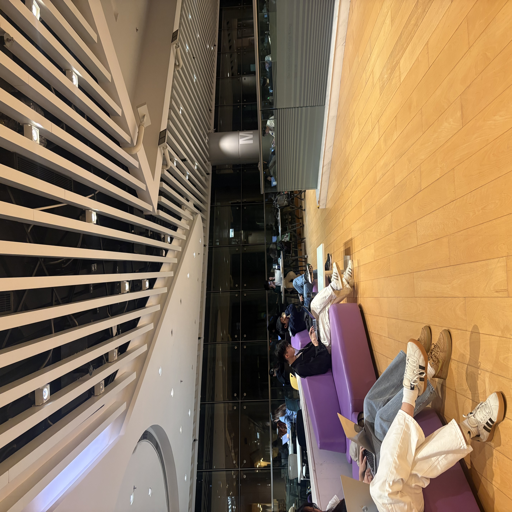

In [6]:
from google.colab import files
from PIL import Image
import io

uploaded = files.upload()

filename = next(iter(uploaded))

original = Image.open(
    io.BytesIO(uploaded[filename])
).convert("RGB")

original = original.resize((512, 512))

display(original)

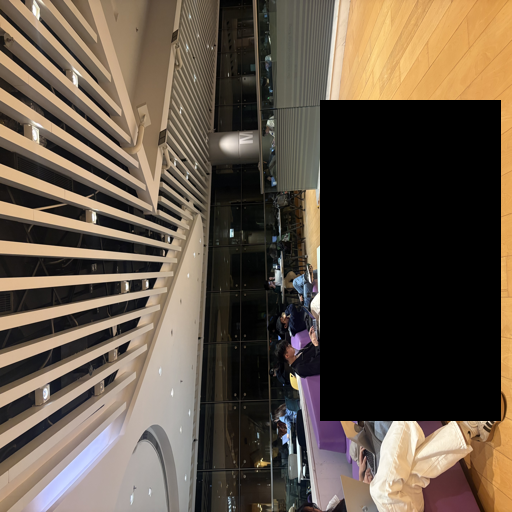

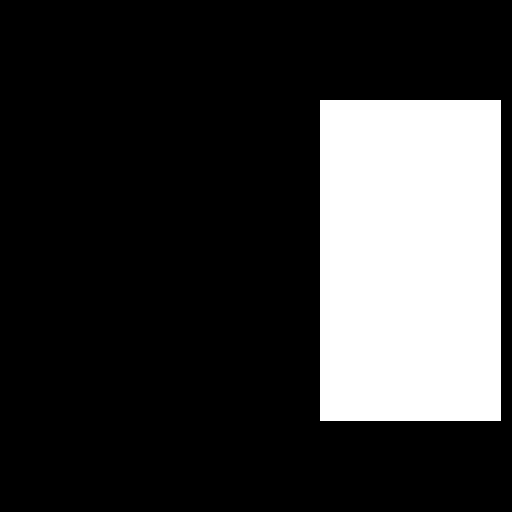

In [7]:
import numpy as np
from PIL import Image, ImageDraw

mask = Image.new("L", (512, 512), 0)
draw = ImageDraw.Draw(mask)

# White = region to inpaint
draw.rectangle((320, 100, 500, 420), fill=255)

masked = np.array(original).copy()
mask_np = np.array(mask) > 0

masked[mask_np] = 0

display(Image.fromarray(masked))
display(mask)

  0%|          | 0/25 [00:00<?, ?it/s]

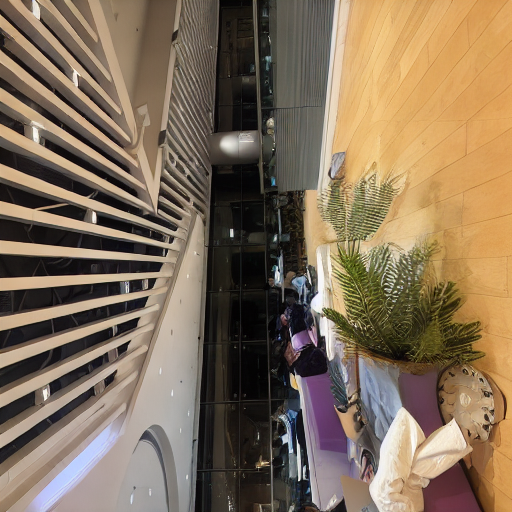

In [8]:
generator = torch.Generator(
    device="cpu"
).manual_seed(42)

prompt = (
    "A realistic indoor room, natural furniture, "
    "consistent lighting, photorealistic"
)

result = pipe(
    prompt=prompt,
    image=original,
    mask_image=mask,
    num_inference_steps=25,
    guidance_scale=7.5,
    generator=generator
).images[0]

display(result)

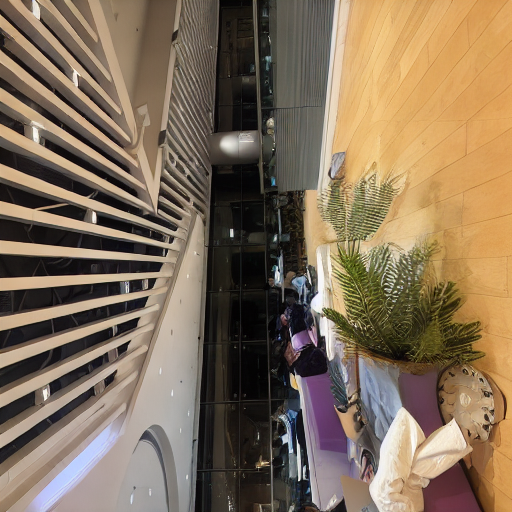

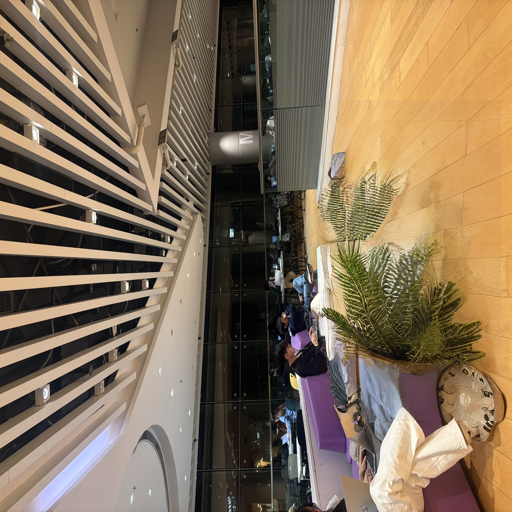

In [9]:
import numpy as np
from PIL import Image

original_np = np.array(original)
result_np = np.array(result)

# Condition B: full decoded output
full_output = result

# Condition C: replace only masked pixels
selective_np = original_np.copy()
selective_np[mask_np] = result_np[mask_np]

selective_output = Image.fromarray(selective_np)

display(full_output)
display(selective_output)

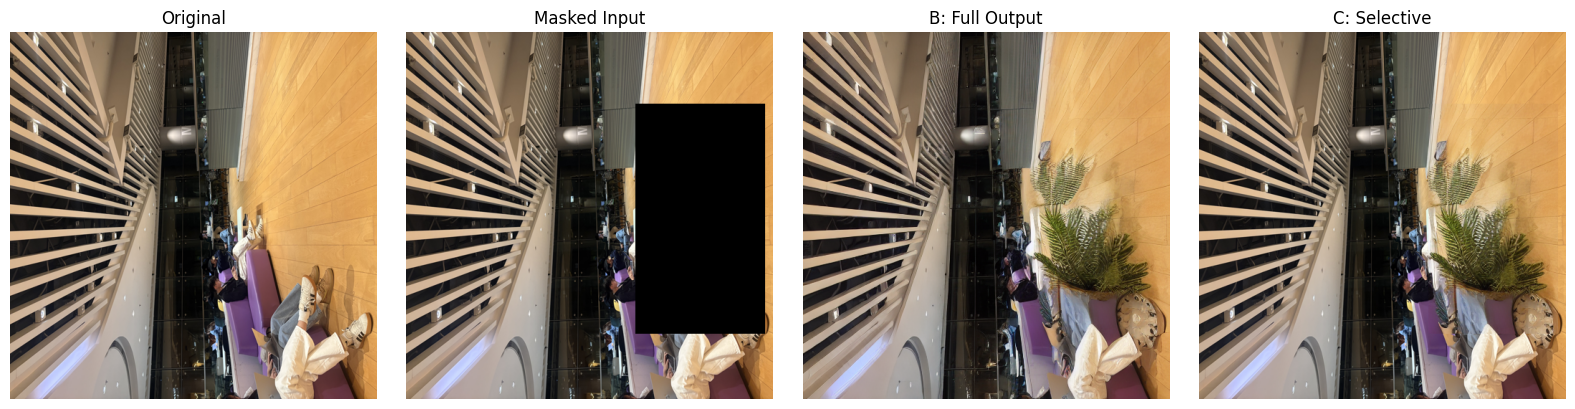

In [10]:
import matplotlib.pyplot as plt

images = [
    original,
    Image.fromarray(masked),
    full_output,
    selective_output
]

titles = [
    "Original",
    "Masked Input",
    "B: Full Output",
    "C: Selective"
]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [11]:
from pathlib import Path

output_dir = Path("/content/inpainting_results")
output_dir.mkdir(exist_ok=True)

original.save(output_dir / "original.png")
mask.save(output_dir / "hole_mask.png")
full_output.save(output_dir / "full_output.png")
selective_output.save(output_dir / "selective_output.png")

print("Results saved to:", output_dir)

Results saved to: /content/inpainting_results


In [12]:
import numpy as np

original_np = np.asarray(original).astype(np.float32)
full_np = np.asarray(full_output).astype(np.float32)
selective_np = np.asarray(selective_output).astype(np.float32)

# True = unmasked (visible) region
visible_mask = ~mask_np

# Pixel-wise absolute error
error_B = np.abs(original_np - full_np).mean(axis=2)
error_C = np.abs(original_np - selective_np).mean(axis=2)

mae_B = error_B[visible_mask].mean()
mae_C = error_C[visible_mask].mean()

print(f"Condition B - Visible-region MAE: {mae_B:.4f}")
print(f"Condition C - Visible-region MAE: {mae_C:.4f}")

Condition B - Visible-region MAE: 7.7641
Condition C - Visible-region MAE: 0.0000


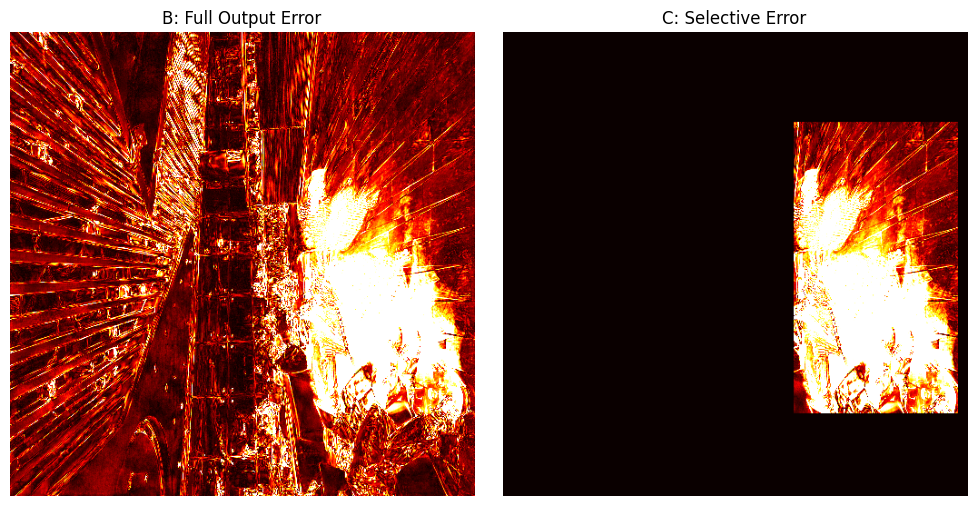

In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(error_B, cmap="hot", vmin=0, vmax=30)
axes[0].set_title("B: Full Output Error")

axes[1].imshow(error_C, cmap="hot", vmin=0, vmax=30)
axes[1].set_title("C: Selective Error")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [14]:
import numpy as np

def masked_psnr(reference, prediction, valid_mask):
    ref = np.asarray(reference).astype(np.float64)
    pred = np.asarray(prediction).astype(np.float64)

    squared_error = ((ref - pred) ** 2).mean(axis=2)
    mse = squared_error[valid_mask].mean()

    if mse == 0:
        return float("inf")

    return 10 * np.log10((255.0 ** 2) / mse)


psnr_B = masked_psnr(
    original, full_output, visible_mask
)

psnr_C = masked_psnr(
    original, selective_output, visible_mask
)

print(f"B - Visible PSNR: {psnr_B:.2f} dB")
print(f"C - Visible PSNR: {psnr_C:.2f} dB")

B - Visible PSNR: 25.85 dB
C - Visible PSNR: inf dB


In [15]:
from skimage.metrics import structural_similarity as ssim

original_arr = np.asarray(original)
full_arr = np.asarray(full_output)
selective_arr = np.asarray(selective_output)

ssim_B = ssim(
    original_arr,
    full_arr,
    channel_axis=2,
    data_range=255
)

ssim_C = ssim(
    original_arr,
    selective_arr,
    channel_axis=2,
    data_range=255
)

print(f"B - Full-image SSIM: {ssim_B:.4f}")
print(f"C - Full-image SSIM: {ssim_C:.4f}")

B - Full-image SSIM: 0.7307
C - Full-image SSIM: 0.8524


In [16]:
!pip -q install lpips
import lpips
import torch
import numpy as np

loss_fn = lpips.LPIPS(net="alex").to("cuda").eval()

def to_tensor(img):
    arr = np.array(img).astype(np.float32) / 127.5 - 1.0
    tensor = torch.from_numpy(arr).permute(2, 0, 1)
    return tensor.unsqueeze(0).to("cuda")

with torch.no_grad():
    original_t = to_tensor(original)
    full_t = to_tensor(full_output)
    selective_t = to_tensor(selective_output)

    lpips_B = loss_fn(original_t, full_t).item()
    lpips_C = loss_fn(original_t, selective_t).item()

print(f"B - Full-image LPIPS: {lpips_B:.4f}")
print(f"C - Full-image LPIPS: {lpips_C:.4f}")

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 124MB/s]


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth
B - Full-image LPIPS: 0.1959
C - Full-image LPIPS: 0.1471


In [17]:
from pathlib import Path

Path("src/inpainting").mkdir(parents=True, exist_ok=True)
Path("evaluation").mkdir(exist_ok=True)
Path("notebooks").mkdir(exist_ok=True)

Path("src/inpainting/__init__.py").touch()
Path("evaluation/__init__.py").touch()

In [18]:
%%writefile src/inpainting/pipeline.py

import torch
import numpy as np
from PIL import Image
from diffusers import StableDiffusionInpaintPipeline


MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-inpainting"


def load_inpainting_model():
    pipe = StableDiffusionInpaintPipeline.from_pretrained(
        MODEL_ID,
        torch_dtype=torch.float16
    )
    pipe.enable_model_cpu_offload()
    return pipe


def inpaint(
    pipe,
    warped_rgb,
    hole_mask,
    prompt="A realistic indoor room, natural furniture, consistent lighting",
    seed=42,
    num_inference_steps=25
):
    """
    warped_rgb: RGB uint8 ndarray, shape (H, W, 3)
    hole_mask: Boolean ndarray, shape (H, W)
               True = pixels requiring inpainting

    Returns:
        raw_inpainted_rgb: RGB uint8 ndarray
    """

    image_array = np.asarray(warped_rgb, dtype=np.uint8)
    mask_array = np.asarray(hole_mask, dtype=bool)

    assert image_array.ndim == 3
    assert image_array.shape[2] == 3
    assert mask_array.shape == image_array.shape[:2]

    height, width = mask_array.shape
    assert height % 8 == 0 and width % 8 == 0

    image = Image.fromarray(image_array)
    mask = Image.fromarray(
        (mask_array.astype(np.uint8) * 255)
    )

    generator = torch.Generator(device="cpu").manual_seed(seed)

    result = pipe(
        prompt=prompt,
        image=image,
        mask_image=mask,
        num_inference_steps=num_inference_steps,
        guidance_scale=7.5,
        generator=generator
    ).images[0]

    return np.asarray(result, dtype=np.uint8)

Writing src/inpainting/pipeline.py


In [19]:
%%writefile src/inpainting/compositing.py

import numpy as np


def selective_composite(
    warped_rgb,
    raw_inpainted_rgb,
    hole_mask
):
    """
    Replace only pixels inside the hole mask.

    True  = inpainted region
    False = preserve original pixels
    """

    original = np.asarray(warped_rgb)
    generated = np.asarray(raw_inpainted_rgb)
    mask = np.asarray(hole_mask, dtype=bool)

    assert original.shape == generated.shape
    assert mask.shape == original.shape[:2]

    completed = original.copy()
    completed[mask] = generated[mask]

    return completed

Writing src/inpainting/compositing.py


In [20]:
%%writefile evaluation/image_metrics.py

import numpy as np


def masked_mae(reference, prediction, valid_mask):
    ref = np.asarray(reference).astype(np.float64)
    pred = np.asarray(prediction).astype(np.float64)
    mask = np.asarray(valid_mask, dtype=bool)

    assert ref.shape == pred.shape
    assert mask.shape == ref.shape[:2]
    assert mask.any(), "No valid pixels in mask"

    error = np.abs(ref - pred).mean(axis=2)
    return float(error[mask].mean())


def masked_psnr(reference, prediction, valid_mask):
    ref = np.asarray(reference).astype(np.float64)
    pred = np.asarray(prediction).astype(np.float64)
    mask = np.asarray(valid_mask, dtype=bool)

    assert ref.shape == pred.shape
    assert mask.shape == ref.shape[:2]
    assert mask.any(), "No valid pixels in mask"

    mse_map = ((ref - pred) ** 2).mean(axis=2)
    mse = mse_map[mask].mean()

    if mse == 0:
        return float("inf")

    return float(10 * np.log10(255.0 ** 2 / mse))

Writing evaluation/image_metrics.py


MAE: 0.0
PSNR: inf


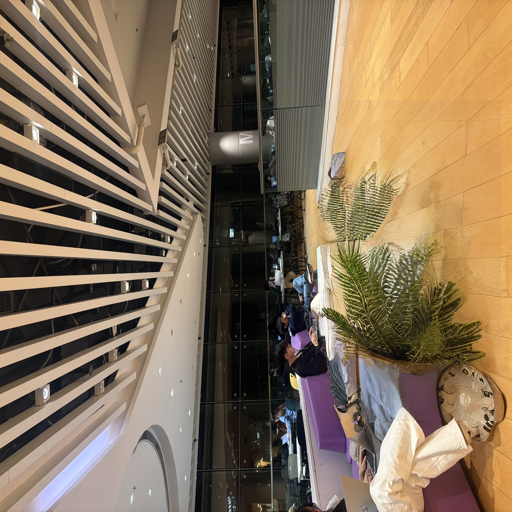

In [21]:
from src.inpainting.compositing import selective_composite
from evaluation.image_metrics import masked_mae, masked_psnr

warped_rgb = np.asarray(original)
raw_inpainted_rgb = np.asarray(full_output)
hole_mask = np.asarray(mask) > 0

completed_rgb = selective_composite(
    warped_rgb,
    raw_inpainted_rgb,
    hole_mask
)

visible_mask = ~hole_mask

print("MAE:", masked_mae(
    warped_rgb, completed_rgb, visible_mask
))

print("PSNR:", masked_psnr(
    warped_rgb, completed_rgb, visible_mask
))

display(Image.fromarray(completed_rgb))

In [22]:
import shutil

shutil.make_archive(
    "/content/member2_modules",
    "zip",
    ".",
    "src"
)

shutil.make_archive(
    "/content/member2_evaluation",
    "zip",
    ".",
    "evaluation"
)

from google.colab import files

files.download("/content/member2_modules.zip")
files.download("/content/member2_evaluation.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>